# MODELIZACIÓN PD: XGBOOST Y LIGHTGBM

Este notebook busca un modelo de **probabilidad de impago (PD)** que ordene mejor a los clientes que el modelo actual del notebook 05: una regresión logística Ridge con splines (Gini externo 0,4225, Brier 0,1435).

**Candidatos:** XGBoost y LightGBM

**Reglas:**

* Mismo tablón, misma partición train/test 70/30 y mismos 5 folds que el notebook 05, para que la comparación sea 1 a 1.
* Métrica principal: **ROC-AUC**, reportada también como **Gini** (`2·AUC − 1`). Controles: **Brier**, **log loss** y **calibración por deciles**, porque la PD alimenta la pérdida esperada y su nivel tiene que ser creíble.
* El ganador se elige **solo con validación cruzada** sobre train. El test interno y la validación externa se usan una única vez, al final.

## IMPORTAR PAQUETES

**Qué hace:** importa las librerías, fija la semilla y comprueba las versiones de XGBoost y LightGBM.
**Por qué:** las versiones quedan registradas en la salida; un modelo de boosting entrenado con una versión no siempre
se carga igual con otra.

In [1]:
import time
import warnings
from pathlib import Path

import joblib
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import SplineTransformer
from xgboost import XGBClassifier

pd.set_option('display.float_format', lambda v: '%.4f' % v)
warnings.filterwarnings('ignore', message='X does not have valid feature names')

SEMILLA = 42

print(f'scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | lightgbm {lightgbm.__version__}')

scikit-learn 1.9.0 | xgboost 3.4.1 | lightgbm 4.7.0


## IMPORTAR LOS DATOS

**Qué hace:** carga el tablón **sin transformar** (15 variables crudas + `target_pd`)

**Por qué:** el preprocesado se aplica dentro del pipeline, ajustado solo con los datos de entrenamiento de cada fold.

**Qué esperar:** 83.250 préstamos y una tasa de impago cercana al 20%.

In [2]:
df = pd.read_pickle('../02_datos/03_Entrenamiento/df_tablon_pd_sin_transformar.pkl')
x = df.drop(columns='target_pd')
y = df.target_pd
print(f'{df.shape[0]} préstamos, {x.shape[1]} variables, tasa de impago {y.mean():.1%}')

83250 préstamos, 15 variables, tasa de impago 19.9%


## PARTICIÓN Y VALIDACIÓN CRUZADA

**Qué hace:** separa el 30% como test interno y define los 5 folds estratificados.

**Por qué:** con la misma semilla que el notebook 05, train, test y cada fold contienen exactamente los mismos
préstamos. Así se puede comparar fold a fold contra el modelo con splines.

**Qué esperar:** 58.275 filas de train y 24.975 de test, las dos con tasa de impago de 0,199.

In [3]:
train_x, test_x, train_y, test_y = train_test_split(x, y, test_size=0.3, stratify=y, random_state=SEMILLA)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

pd.DataFrame({'filas': [len(train_y), len(test_y)], 'tasa_impago': [train_y.mean(), test_y.mean()]},
             index=['train', 'test'])

,filas,tasa_impago
train,58275,0.1990
test,24975,0.1990


## PREPROCESADOR Y MÉTRICAS

**Qué hace:** carga el preprocesador de la fase de transformación (one-hot, ordinal, Yeo-Johnson, escalado) y define
las métricas que se calculan en cada fold.
**Por qué:** `clone` copia la configuración pero no lo aprendido, así que el preprocesador se reajusta en cada fold.
A los árboles no les afectan Yeo-Johnson ni el escalado, porque esas transformaciones no cambian el orden de los valores
y un árbol solo mira el orden para elegir sus cortes. Usar el mismo preprocesador mantiene la comparación pareja.

**Métricas** (todas en la misma pasada de validación cruzada):

| Clave | Qué mide | Mejor si |
|---|---|---|
| `auc` | Ordenamiento: probabilidad de que un moroso tenga más PD que un pagador. Gini = 2·AUC − 1 | mayor |
| `brier` | Error cuadrático medio entre la PD y el desenlace (0/1). Mezcla orden y nivel | menor |
| `log_loss` | Como el Brier, pero castiga mucho más las PD muy seguras y equivocadas | menor |
| `pr_auc` | Área bajo la curva precisión-recall. Complementaria; con 20% de morosos el AUC ya es informativo | mayor |
| `accuracy_05`, `precision_05`, `recall_05`, `f1_05` | Métricas de clasificación **cortando en PD = 0,5** | mayor |

Las métricas `_05`  se reportan solo como referencia.
sklearn devuelve el Brier y el log loss con signo negativo (`neg_...`) para que "mayor sea mejor" en todas. La función
`resumen_cv` les vuelve a dar el signo positivo.

In [4]:
preprocesador = clone(joblib.load('../05_modelos/preprocesador.joblib'))

METRICAS = {
    'auc': 'roc_auc',
    'brier': 'neg_brier_score',
    'log_loss': 'neg_log_loss',
    'pr_auc': 'average_precision',
    'accuracy_05': 'accuracy',
    'precision_05': 'precision',
    'recall_05': 'recall',
    'f1_05': 'f1',
}
METRICAS_NEGATIVAS = {'brier', 'log_loss'}


def resumen_cv(resultados, prefijo='test_'):
    """Media, desvío y media de train de cada métrica de cross_validate, con el signo corregido."""
    filas = {}
    for metrica in METRICAS:
        signo = -1 if metrica in METRICAS_NEGATIVAS else 1
        cv_vals = signo * np.asarray(resultados[f'{prefijo}{metrica}'])
        train_vals = signo * np.asarray(resultados[f'train_{metrica}'])
        filas[metrica] = {'media_cv': cv_vals.mean(), 'std_cv': cv_vals.std(), 'media_train': train_vals.mean()}
    tabla = pd.DataFrame(filas).T
    tabla['gap_train_cv'] = np.where(tabla.index.isin(list(METRICAS_NEGATIVAS)),
                                     tabla['media_cv'] - tabla['media_train'],
                                     tabla['media_train'] - tabla['media_cv'])
    return tabla


def ks_estadistico(y_true, y_pred):
    """Máxima distancia entre las distribuciones acumuladas de PD de morosos y pagadores."""
    fpr, tpr, _ = roc_curve(y_true, y_pred)
    return np.max(tpr - fpr)

## BASELINE: LOGÍSTICA CON SPLINES (MODELO ACTUAL)

**Qué hace:** reconstruye el pipeline ganador del notebook 05 (splines cúbicas con 8 nudos en `principal`, `dti`,
`imp_cuota` y `tipo_interes`, más logística Ridge con `C ≈ 0,316`) y lo evalúa con los 5 folds y todas las métricas.
**Por qué:** es la vara que hay que superar. No se vuelve a buscar hiperparámetros, se usan los ya elegidos.
**Qué esperar:** un AUC medio de alrededor de 0,710 (0,7098 en el notebook 05) y el AUC de cada fold, que sirve
después para la comparación pareada fold a fold. `gap_train_cv` positivo indica que train rinde mejor que CV, señal
de sobreajuste si es grande.

In [5]:
COLUMNAS_SPLINE = ['yj__principal', 'yj__dti', 'yj__imp_cuota', 'ss__tipo_interes']

pipe_splines = Pipeline([
    ('preprocesador', clone(preprocesador)),
    ('splines', ColumnTransformer(
        [('spl', SplineTransformer(n_knots=8, degree=3, knots='quantile', include_bias=False), COLUMNAS_SPLINE)],
        remainder='passthrough',
        verbose_feature_names_out=False,
    ).set_output(transform='pandas')),
    ('algoritmo', LogisticRegression(solver='saga', l1_ratio=0, C=10 ** -0.5, max_iter=3000,
                                     random_state=SEMILLA)),
])

inicio = time.time()
cv_splines = cross_validate(pipe_splines, train_x, train_y, cv=cv, scoring=METRICAS,
                            return_train_score=True, n_jobs=-1)
print(f'Validación cruzada del baseline en {time.time() - inicio:.0f} s')

auc_folds = pd.DataFrame({'Logística + splines': cv_splines['test_auc']},
                         index=[f'fold {i}' for i in range(1, 6)])
display(auc_folds.T)
resumen_cv(cv_splines)

Validación cruzada del baseline en 24 s


,fold 1,fold 2,fold 3,fold 4,fold 5
Logística + splines,0.7023,0.7066,0.7131,0.7177,0.7094


,media_cv,std_cv,media_train,gap_train_cv
auc,0.7098,0.0053,0.7123,0.0025
brier,0.1449,0.0007,0.1445,0.0004
log_loss,0.4536,0.0026,0.4523,0.0013
pr_auc,0.3714,0.0068,0.3751,0.0037
accuracy_05,0.8034,0.0012,0.8037,0.0002
precision_05,0.5541,0.0266,0.5604,0.0062
recall_05,0.0621,0.0051,0.0624,0.0003
f1_05,0.1116,0.0087,0.1122,0.0006


**Lectura.** . El sobreajuste es mínimo: train supera a CV en solo 0,0025 de AUC.

Las métricas cortando en 0,5 muestran por qué no sirven para una PD. La *accuracy* de 0,803 es prácticamente la de predecir "no impaga" para todos (0,801), y el *recall* de 0,062 indica que solo el 6% de los morosos supera una PD de 0,5.
El modelo no es malo: ordena bien (AUC 0,71). El corte en 0,5 no tiene sentido con un 20% de morosos.

**La vara para los challengers:** AUC CV > 0,7098 (Gini 0,4196), sin empeorar el Brier (0,1449) ni el log loss (0,4536).

## PROBE: CURVAS DE VALIDACIÓN

**Qué es el boosting.** XGBoost y LightGBM entrenan **árboles chicos en secuencia**. Cada árbol nuevo se ajusta a los
errores que dejaron los anteriores (el gradiente de la pérdida) y su aporte se multiplica por la tasa de aprendizaje
(`learning_rate`). Los dos aprenden lo mismo y difieren en cómo crecen los árboles:

* **XGBoost** crece **por niveles**: parte todas las hojas de un nivel antes de pasar al siguiente. La complejidad se
  controla con `max_depth`, y un árbol de profundidad *d* tiene hasta 2^*d* hojas.
* **LightGBM** crece **por hoja**: siempre parte la hoja que más reduce el error, aunque el árbol quede desbalanceado.
  La complejidad se controla con `num_leaves`.

**Qué hace:** para cada modelo mueve **un solo** hiperparámetro de complejidad, con los demás fijos (300 árboles,`learning_rate=0,05`), y mide el AUC en train y en CV con 3 folds.

**Por qué:** acota el espacio de búsqueda a la zona donde la CV es mejor y la distancia entre train y CV todavía es chica.

**Qué esperar:** vemos que la curva de train (qué tan bien el modelo ordena los datos con los que aprendió) sube sin parar, cv (predice cómo va a andar en producción) empieza arriba y sólo baja. Eso es sobreajuste, el modelo memoriza ruido del train.

Ningún punto de CV supera la línea gris. Lo mejor que logran los boosters es empatar con la logística con splines


Probe terminado en 84 s


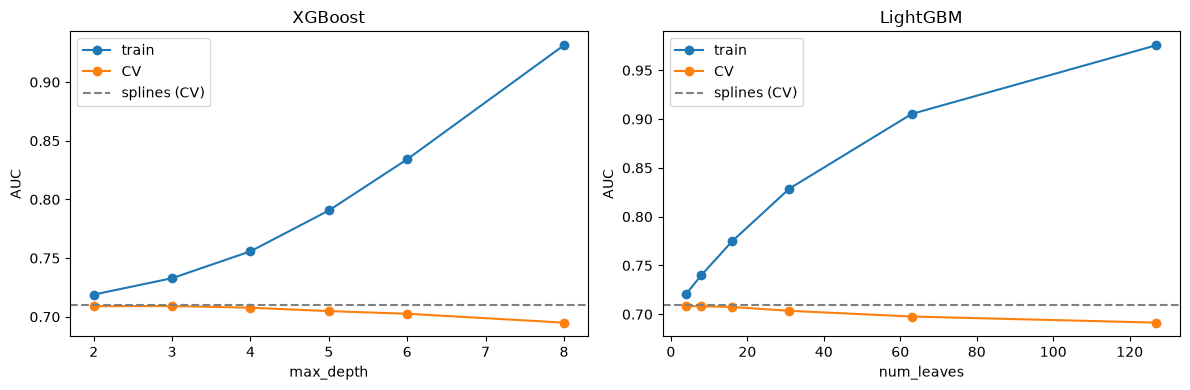

XGBoost


,auc_train,auc_cv,std_cv,gap
max_depth,,,,
2,0.7189,0.7090,0.0051,0.0099
3,0.7329,0.7092,0.0049,0.0237
4,0.7558,0.7077,0.0044,0.0481
5,0.7906,0.7048,0.0029,0.0858
6,0.8343,0.7026,0.0025,0.1317
8,0.9315,0.6950,0.0028,0.2364


LightGBM


,auc_train,auc_cv,std_cv,gap
num_leaves,,,,
4,0.7209,0.7086,0.0053,0.0123
8,0.7402,0.7082,0.0052,0.0320
16,0.7747,0.7075,0.0045,0.0672
31,0.8288,0.7035,0.0046,0.1253
63,0.9053,0.6977,0.0042,0.2076
127,0.9757,0.6914,0.0037,0.2843


In [6]:
from sklearn.model_selection import validation_curve

cv_probe = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)

pipe_xgb = Pipeline([
    ('preprocesador', clone(preprocesador)),
    ('algoritmo', XGBClassifier(n_estimators=300, learning_rate=0.05, tree_method='hist', eval_metric='logloss',
                                n_jobs=1, random_state=SEMILLA)),
])
pipe_lgbm = Pipeline([
    ('preprocesador', clone(preprocesador)),
    ('algoritmo', LGBMClassifier(n_estimators=300, learning_rate=0.05, n_jobs=1, verbose=-1,
                                 random_state=SEMILLA)),
])

probes = {
    'XGBoost': (pipe_xgb, 'algoritmo__max_depth', [2, 3, 4, 5, 6, 8]),
    'LightGBM': (pipe_lgbm, 'algoritmo__num_leaves', [4, 8, 16, 31, 63, 127]),
}

inicio = time.time()
resultados_probe = {}
for nombre, (pipe, parametro, valores) in probes.items():
    auc_train, auc_cv = validation_curve(pipe, train_x, train_y, param_name=parametro, param_range=valores,
                                         cv=cv_probe, scoring='roc_auc', n_jobs=-1)
    resultados_probe[nombre] = pd.DataFrame({'auc_train': auc_train.mean(axis=1), 'auc_cv': auc_cv.mean(axis=1),
                                             'std_cv': auc_cv.std(axis=1)},
                                            index=pd.Index(valores, name=parametro.split('__')[1]))
    resultados_probe[nombre]['gap'] = resultados_probe[nombre]['auc_train'] - resultados_probe[nombre]['auc_cv']
print(f'Probe terminado en {time.time() - inicio:.0f} s')

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for eje, (nombre, tabla) in zip(ejes, resultados_probe.items()):
    eje.plot(tabla.index, tabla['auc_train'], marker='o', label='train')
    eje.plot(tabla.index, tabla['auc_cv'], marker='o', label='CV')
    eje.axhline(0.7098, color='grey', linestyle='--', label='splines (CV)')
    eje.set_title(nombre)
    eje.set_xlabel(tabla.index.name)
    eje.set_ylabel('AUC')
    eje.legend()
plt.tight_layout()
plt.show()

for nombre, tabla in resultados_probe.items():
    print(nombre)
    display(tabla)

## BÚSQUEDA DE HIPERPARÁMETROS

**Qué hace:** busca los hiperparámetros de XGBoost y LightGBM con `RandomizedSearchCV` sobre los mismos 5 folds del baseline, y elige la configuración con la regla del error estándar.
**Por qué:** el probe mostró que la CV solo empeora al complejizar el árbol: el óptimo está en la zona simple, así que buscar en todo el rango desperdicia presupuesto en configuraciones que memorizan. La búsqueda aplica las tres ideas del probe:

* **Sesgo-varianza:** el espacio se recorta a la zona donde el gap train-CV era chico (`max_depth` de 1 a 4, `num_leaves` de 2 a 16).
* **Regularización:** además de la profundidad, la búsqueda mueve las palancas que frenan la memorización: `min_child_weight` / `min_child_samples` (mínimo de datos por hoja), `reg_lambda` y `reg_alpha` (penalización L2 y L1 sobre los pesos de las hojas), `gamma` / `min_split_gain` (mejora mínima para partir), `subsample` y `colsample_bytree` (cada árbol ve solo una parte de las filas y las columnas). El número de árboles y la `learning_rate` se buscan juntos, porque se compensan.
* **Validación cruzada:** cada candidato se evalúa con los 5 folds estratificados, con `return_train_score=True` para ver el gap de cada uno. La búsqueda aleatoria cubre mejor un espacio de muchos hiperparámetros que una grilla con el mismo presupuesto (Bergstra y Bengio, 2012).

**Regla de selección (1 error estándar):** el mejor AUC medio de CV puede ganar por azar entre decenas de candidatos. Entre los que quedan a menos de 1 error estándar del mejor, se elige el de **menor gap train-CV**, es decir, el menos sobreajustado. La regla viene de Hastie, Tibshirani y Friedman, *The Elements of Statistical Learning*, capítulo 7.
**Qué esperar:** un AUC de CV igual o apenas superior al 0,7098 del baseline, con un gap bajo.

In [7]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

N_CANDIDATOS = 40

pipe_xgb = Pipeline([
    ('preprocesador', clone(preprocesador)),
    ('algoritmo', XGBClassifier(tree_method='hist', eval_metric='logloss', n_jobs=1, random_state=SEMILLA)),
])
pipe_lgbm = Pipeline([
    ('preprocesador', clone(preprocesador)),
    ('algoritmo', LGBMClassifier(subsample_freq=1, n_jobs=1, verbose=-1, random_state=SEMILLA)),
])

espacios = {
    'XGBoost': (pipe_xgb, {
        'algoritmo__max_depth': randint(1, 5),
        'algoritmo__n_estimators': randint(100, 601),
        'algoritmo__learning_rate': loguniform(0.01, 0.1),
        'algoritmo__min_child_weight': loguniform(1, 200),
        'algoritmo__reg_lambda': loguniform(1, 100),
        'algoritmo__reg_alpha': loguniform(1e-3, 10),
        'algoritmo__gamma': loguniform(1e-3, 5),
        'algoritmo__subsample': uniform(0.5, 0.5),
        'algoritmo__colsample_bytree': uniform(0.5, 0.5),
    }),
    'LightGBM': (pipe_lgbm, {
        'algoritmo__num_leaves': randint(2, 17),
        'algoritmo__n_estimators': randint(100, 601),
        'algoritmo__learning_rate': loguniform(0.01, 0.1),
        'algoritmo__min_child_samples': randint(20, 1001),
        'algoritmo__reg_lambda': loguniform(1, 100),
        'algoritmo__reg_alpha': loguniform(1e-3, 10),
        'algoritmo__min_split_gain': loguniform(1e-3, 1),
        'algoritmo__subsample': uniform(0.5, 0.5),
        'algoritmo__colsample_bytree': uniform(0.5, 0.5),
    }),
}

inicio = time.time()
busquedas = {}
for nombre, (pipe, espacio) in espacios.items():
    busqueda = RandomizedSearchCV(pipe, espacio, n_iter=N_CANDIDATOS, scoring='roc_auc', cv=cv,
                                  return_train_score=True, refit=False, n_jobs=-1, random_state=SEMILLA)
    busqueda.fit(train_x, train_y)
    busquedas[nombre] = pd.DataFrame(busqueda.cv_results_)
    print(f'{nombre}: {N_CANDIDATOS} candidatos x 5 folds en {time.time() - inicio:.0f} s acumulados')

XGBoost: 40 candidatos x 5 folds en 492 s acumulados


LightGBM: 40 candidatos x 5 folds en 934 s acumulados


In [8]:
elegidos = {}
for nombre, resultados in busquedas.items():
    resultados = resultados.assign(gap=resultados['mean_train_score'] - resultados['mean_test_score'])
    mejor = resultados.loc[resultados['mean_test_score'].idxmax()]
    error_estandar = mejor['std_test_score'] / np.sqrt(5)
    equivalentes = resultados[resultados['mean_test_score'] >= mejor['mean_test_score'] - error_estandar]
    elegidos[nombre] = equivalentes.loc[equivalentes['gap'].idxmin()]
    print(f'{nombre}: mejor AUC CV {mejor.mean_test_score:.4f} (gap {mejor.gap:.4f}), error estándar {error_estandar:.4f}, '
          f'{len(equivalentes)} candidatos equivalentes')

columnas_parametros = {nombre: [c for c in resultados.columns if c.startswith('param_')]
                       for nombre, resultados in busquedas.items()}
tabla_elegidos = pd.DataFrame({nombre: fila[['mean_test_score', 'std_test_score', 'mean_train_score', 'gap']
                                            + columnas_parametros[nombre]]
                               for nombre, fila in elegidos.items()})
tabla_elegidos.index = [i.replace('param_algoritmo__', '') for i in tabla_elegidos.index]
tabla_elegidos

XGBoost: mejor AUC CV 0.7106 (gap 0.0143), error estándar 0.0025, 19 candidatos equivalentes
LightGBM: mejor AUC CV 0.7106 (gap 0.0123), error estándar 0.0025, 28 candidatos equivalentes


,XGBoost,LightGBM
gap,0.0031,0.0056
mean_test_score,0.7082,0.7091
mean_train_score,0.7114,0.7147
colsample_bytree,0.8732,0.5035
gamma,0.2529,NaN
learning_rate,0.0707,0.0324
max_depth,1,NaN
min_child_samples,NaN,668
min_child_weight,5.1151,NaN
min_split_gain,NaN,0.0285


In [9]:
pipes_finales = {}
for nombre, (pipe, _) in espacios.items():
    parametros = {c.replace('param_', ''): elegidos[nombre][c] for c in columnas_parametros[nombre]}
    pipes_finales[nombre] = clone(pipe).set_params(**parametros)

cv_challengers = {nombre: cross_validate(pipe, train_x, train_y, cv=cv, scoring=METRICAS, return_train_score=True,
                                         n_jobs=-1)
                  for nombre, pipe in pipes_finales.items()}

comparacion = pd.DataFrame({'Logística + splines': resumen_cv(cv_splines)['media_cv'],
                            **{nombre: resumen_cv(r)['media_cv'] for nombre, r in cv_challengers.items()}})
display(comparacion)

auc_comparacion = pd.DataFrame({'Logística + splines': cv_splines['test_auc'],
                          **{nombre: r['test_auc'] for nombre, r in cv_challengers.items()}},
                         index=[f'fold {i}' for i in range(1, 6)])
for nombre in cv_challengers:
    diferencia = auc_comparacion[nombre] - auc_comparacion['Logística + splines']
    print(f'{nombre} - splines: diferencia media {diferencia.mean():+.4f}, desvío {diferencia.std():.4f}, '
          f'gana en {(diferencia > 0).sum()} de 5 folds')

,Logística + splines,XGBoost,LightGBM
auc,0.7098,0.7082,0.7091
brier,0.1449,0.1452,0.1450
log_loss,0.4536,0.4544,0.4539
pr_auc,0.3714,0.3695,0.3698
accuracy_05,0.8034,0.8026,0.8029
precision_05,0.5541,0.5751,0.5574
recall_05,0.0621,0.0327,0.0466
f1_05,0.1116,0.0618,0.0859


XGBoost - splines: diferencia media -0.0016, desvío 0.0010, gana en 0 de 5 folds
LightGBM - splines: diferencia media -0.0007, desvío 0.0010, gana en 1 de 5 folds


**Lectura.** La búsqueda de 40 candidatos por modelo tardó unos 16 minutos y no encontró un challenger mejor que el baseline.

* **El máximo no es una mejora.** Los dos modelos llegan a un AUC de CV de 0,7106 en su mejor candidato, 0,0008 sobre el baseline (0,7098). Es el máximo de 40 intentos medidos sobre los mismos folds, y queda dentro de 1 error estándar (0,0025): no se distingue del azar.
* **La regla del error estándar eligió modelos casi mínimos.** XGBoost quedó con `max_depth=1` (275 árboles de un solo corte) y LightGBM con `num_leaves=4`. El gap train-CV bajó a 0,0031 y 0,0056, frente a 0,2364 y 0,2843 en los puntos más complejos del probe: la regularización y la zona acotada eliminaron el sobreajuste.
* **Con la comparación pareada, ninguno supera al baseline.** XGBoost queda 0,0016 por debajo (gana en 0 de 5 folds) y LightGBM 0,0007 por debajo (gana en 1 de 5), con un desvío de la diferencia de 0,0010. El Brier (0,1452 y 0,1450 frente a 0,1449) y el log loss (0,4544 y 0,4539 frente a 0,4536) tampoco mejoran. Ninguno cumple la vara de AUC CV > 0,7098 sin empeorar el Brier ni el log loss.
* **Interpretación (hipótesis).** Un boosting de profundidad 1 es un modelo aditivo: suma una función escalonada por variable, lo mismo que hacen los splines con curvas suaves. Que la búsqueda converja ahí es consistente con un tablón sin interacciones útiles para ordenar mejor.

Con este resultado, el modelo actual (logística con splines) sigue siendo el mejor. Ningún challenger justifica usar el test interno ni la validación externa.

Conclusiones